# Customer Support Complaint Classification: TF-IDF vs. Transformer Embeddings

**Team:** Rayyan Ahemad Mohd (EDA) · Ebelechukwu Chinedu Umezude (Classical Baseline) · Sai Prasad Bandari (Transformer Approach)

**Project goal:** classify e-commerce customer-support complaints into 16 `Category` labels, comparing a classical TF-IDF baseline against a transformer-embeddings approach — not just "which is more accurate," but **is the modern approach's extra accuracy worth its extra computational cost?**

**Hypothesis:** the transformer approach will beat the classical baseline mainly on the rare/semantically overlapping categories, but at a compute cost that may not be justified for the common, easy categories.

This notebook combines all three parts of the team's work into one file, in order:
1. **Exploratory Data Analysis**
2. **Classical Baseline** (TF-IDF + Logistic Regression)
3. **Transformer Approach** (Sentence Embeddings + Logistic Regression)
4. **Combined Comparison & Conclusion**

Full written documentation (goal, dataset, hypothesis, method decisions, detailed results) is in `PROJECT_DOCUMENTATION.pdf`.


---
# Part 1 — Exploratory Data Analysis
*by Rayyan Ahemad Mohd*
---

# Exploratory Data Analysis: E-Commerce Customer Support Complaints

**Team project:** classify e-commerce customer-support complaints into 16 `Category` labels, comparing a classical TF-IDF baseline against a transformer-embeddings approach.

**This notebook's role:** explore the dataset *before* any modeling happens, to understand its shape, spot the class imbalance the whole project studies, and motivate the project's hypothesis with real evidence — not just assumption.

**Dataset:** `ecommerce_customer_support_cleaned.csv` — 1,334 customer complaints, with columns `Complaint` (text), `Category` (16 labels), `Urgency` (4 levels).


## 1. Imports

In [1]:
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

sns.set_style('whitegrid')
print("Libraries loaded.")


Libraries loaded.


## 2. Load & Initial Exploration

In [2]:
df = pd.read_csv('../data/ecommerce_customer_support_cleaned.csv')

print("Shape:", df.shape)
df.head()


Shape: (1334, 3)


,Complaint,Category,Urgency
0,I can’t add a new address — button does nothing.,Account & Shipping,Low
1,Flash sale prices aren’t reflected during chec...,Promotions,Immediate
2,System declined my payment without any reason....,Payments,Immediate
3,The shipping company marked it as delivered to...,Order Tracking,Medium
4,Site logs me out randomly. which is unacceptable,Technical Issues,Medium


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1334 entries, 0 to 1333
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Complaint  1334 non-null   str  
 1   Category   1334 non-null   str  
 2   Urgency    1334 non-null   str  
dtypes: str(3)
memory usage: 114.7 KB


In [4]:
print("Missing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())


Missing values:
 Complaint    0
Category     0
Urgency      0
dtype: int64

Duplicate rows: 0


## 3. Category Distribution

The `Category` column is the classification target for the modeling notebooks. First question: how balanced is it?

Category
Promotions            137
Order Tracking        130
Payments              120
Shipping              108
Account               106
Product Quality       105
Special Requests      104
Inventory             103
Returns                99
Checkout               98
Subscriptions          97
Product Issues         29
Order Issues           29
Technical Issues       25
Account & Shipping     24
Refunds                20
Name: count, dtype: int64


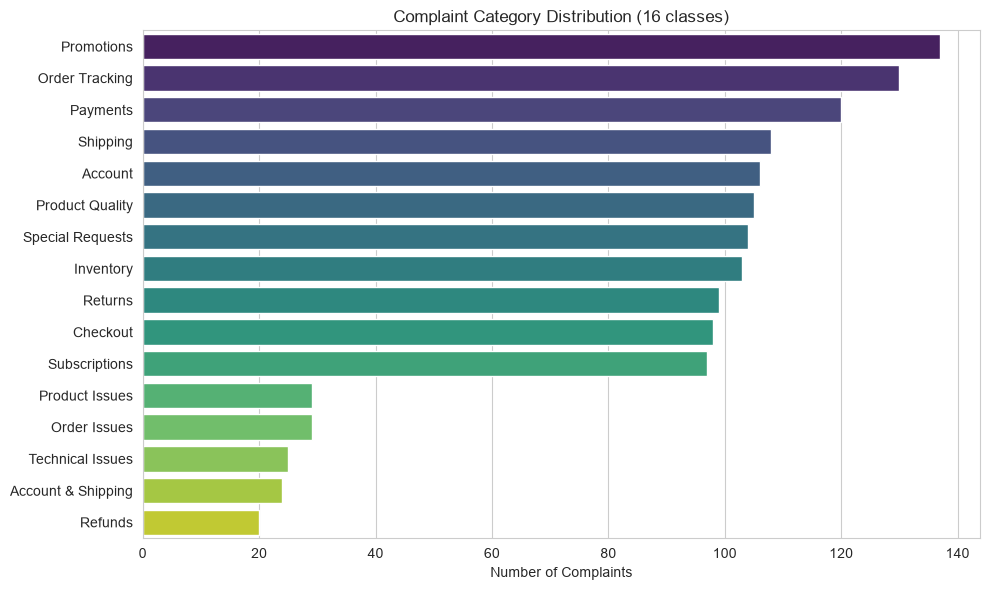

In [5]:
category_counts = df['Category'].value_counts()
print(category_counts)

plt.figure(figsize=(10, 6))
sns.barplot(x=category_counts.values, y=category_counts.index, hue=category_counts.index,
            palette='viridis', legend=False)
plt.title('Complaint Category Distribution (16 classes)')
plt.xlabel('Number of Complaints')
plt.ylabel('')
plt.tight_layout()
plt.show()


In [6]:
# Interpretation
largest = category_counts.idxmax()
smallest = category_counts.idxmin()
ratio = category_counts.max() / category_counts.min()

print(
    f"'{largest}' is the largest category ({category_counts.max()} complaints), "
    f"'{smallest}' is the smallest ({category_counts.min()} complaints) — "
    f"a {ratio:.1f}x imbalance between the biggest and smallest category.\n"
    f"This is the class imbalance the modeling notebooks need to handle explicitly "
    f"(e.g. via class_weight='balanced'), and why macro F1 rather than plain accuracy "
    f"is used as the project's primary metric."
)


'Promotions' is the largest category (137 complaints), 'Refunds' is the smallest (20 complaints) — a 6.8x imbalance between the biggest and smallest category.
This is the class imbalance the modeling notebooks need to handle explicitly (e.g. via class_weight='balanced'), and why macro F1 rather than plain accuracy is used as the project's primary metric.


## 4. Urgency Distribution

`Urgency` isn't the classification target for this project, but it's worth a quick look — it may correlate with category in informative ways.

Urgency
High         563
Medium       360
Immediate    342
Low           69
Name: count, dtype: int64


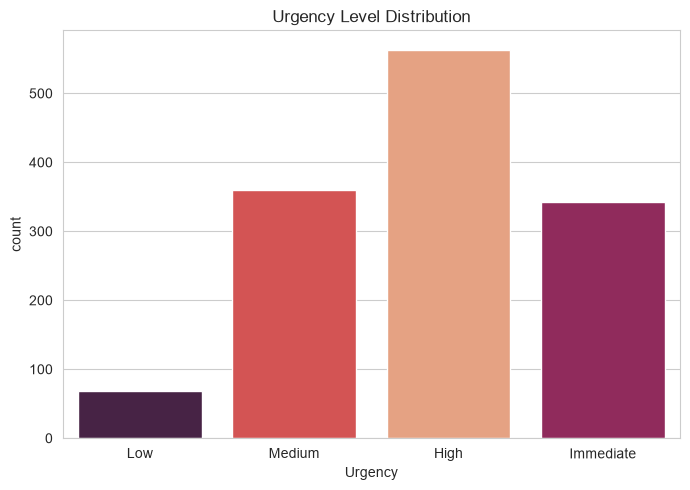

In [7]:
urgency_counts = df['Urgency'].value_counts()
print(urgency_counts)

plt.figure(figsize=(7, 5))
order = ['Low', 'Medium', 'High', 'Immediate']
sns.countplot(x='Urgency', data=df, order=order, hue='Urgency', palette='rocket', legend=False)
plt.title('Urgency Level Distribution')
plt.tight_layout()
plt.show()


## 5. Category vs. Urgency

Is a complaint's category related to how urgent it is? A chi-square test of independence answers this rigorously, not just visually.

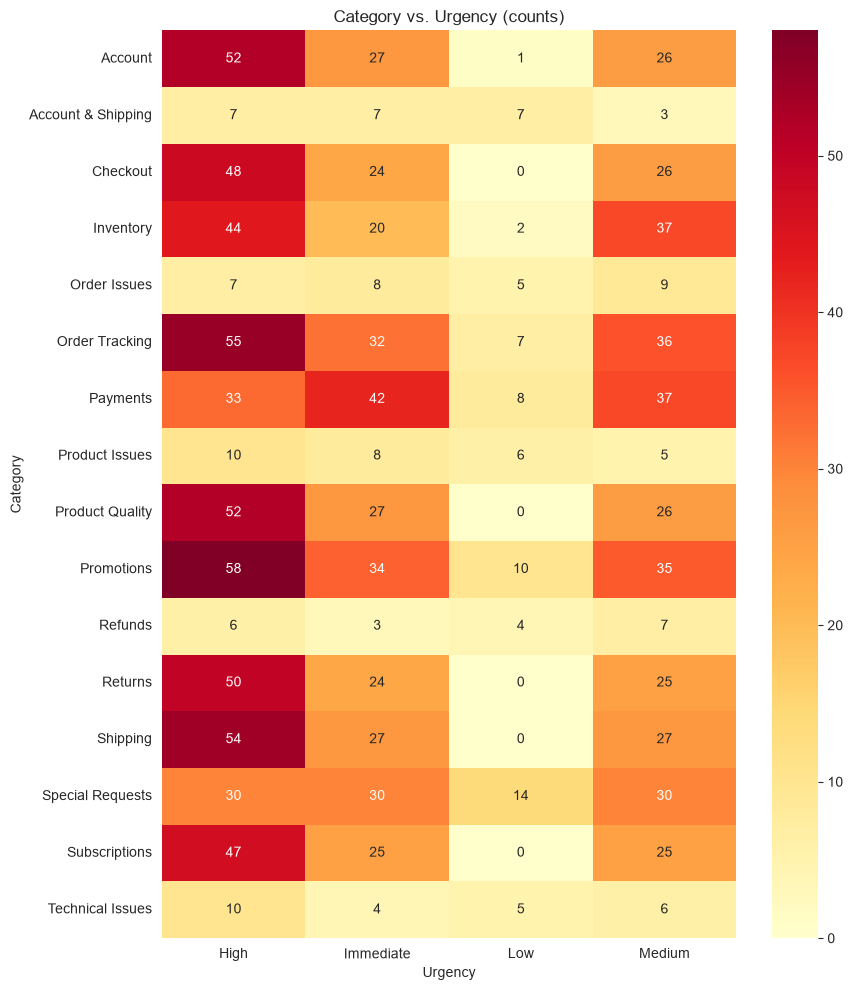

In [8]:
crosstab = pd.crosstab(df['Category'], df['Urgency'])

plt.figure(figsize=(9, 10))
sns.heatmap(crosstab, annot=True, fmt='d', cmap='YlOrRd')
plt.title('Category vs. Urgency (counts)')
plt.tight_layout()
plt.show()


In [9]:
chi2, p_value, dof, expected = chi2_contingency(crosstab)

print(f"Chi-square statistic: {chi2:.2f}")
print(f"Degrees of freedom: {dof}")
print(f"p-value: {p_value:.4f}")
print()
if p_value < 0.05:
    print("p < 0.05 → Category and Urgency are statistically associated (not independent).")
else:
    print("p >= 0.05 → no strong statistical evidence that Category and Urgency are related.")


Chi-square statistic: 154.22
Degrees of freedom: 45
p-value: 0.0000

p < 0.05 → Category and Urgency are statistically associated (not independent).


## 6. Complaint Text Length

How long are these complaints? This matters for the modeling notebooks — the transformer approach truncates/pads to a fixed length, and very short complaints may carry less signal for either approach.

count    1334.000000
mean        6.967766
std         2.990810
min         3.000000
25%         5.000000
50%         6.000000
75%         7.000000
max        20.000000
Name: word_count, dtype: float64


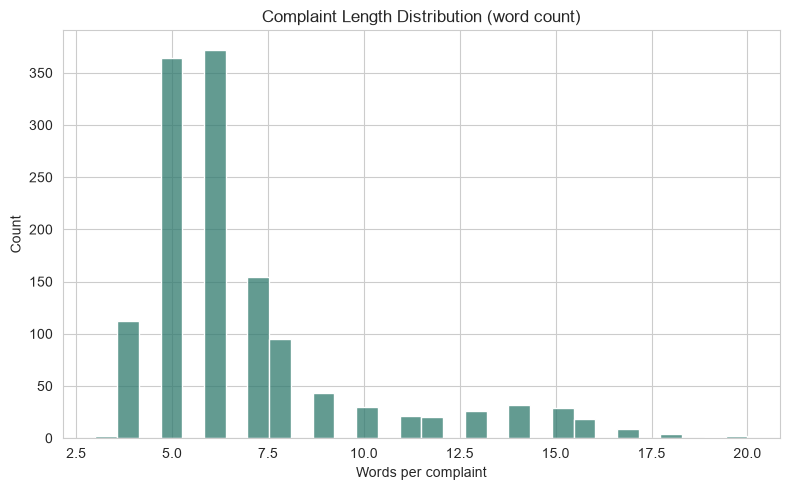

In [10]:
df['word_count'] = df['Complaint'].astype(str).apply(lambda t: len(t.split()))

print(df['word_count'].describe())

plt.figure(figsize=(8, 5))
sns.histplot(df['word_count'], bins=30, color='#2f7a6d')
plt.title('Complaint Length Distribution (word count)')
plt.xlabel('Words per complaint')
plt.tight_layout()
plt.show()


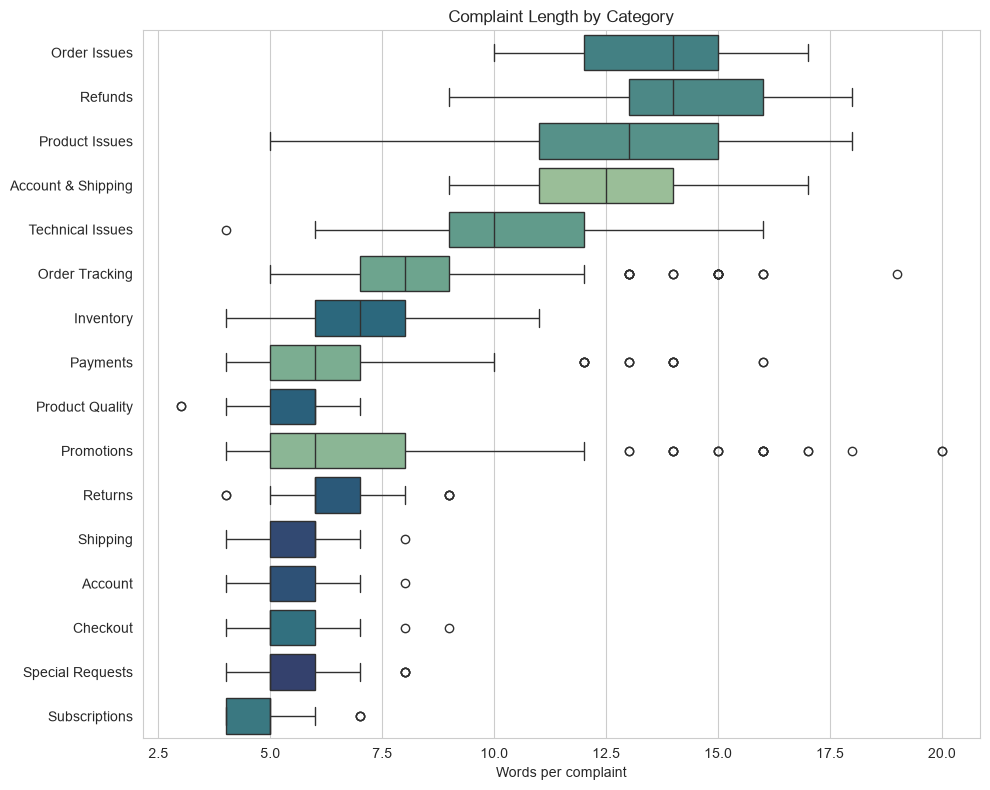

In [11]:
plt.figure(figsize=(10, 8))
order = df.groupby('Category')['word_count'].median().sort_values(ascending=False).index
sns.boxplot(data=df, x='word_count', y='Category', order=order, hue='Category',
            palette='crest', legend=False)
plt.title('Complaint Length by Category')
plt.xlabel('Words per complaint')
plt.ylabel('')
plt.tight_layout()
plt.show()


## 7. Most Common Words (Overall and by Category)

A simple word-frequency check — this is the "plain counting" view that TF-IDF formalizes, and it hints at which categories might be easy (distinctive vocabulary) vs. hard (overlapping vocabulary) for either modeling approach.

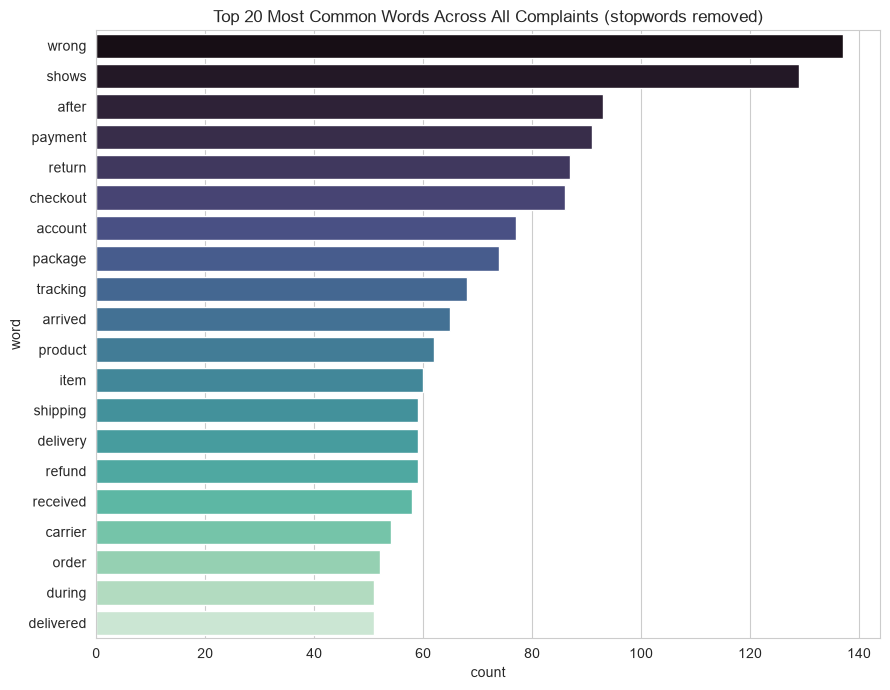

In [12]:
def clean_and_tokenize(text):
    text = str(text).lower()
    text = re.sub(r'[^a-z\s]', '', text)
    return text.split()

all_words = []
for complaint in df['Complaint']:
    all_words.extend(clean_and_tokenize(complaint))

STOPWORDS = {'the', 'a', 'an', 'is', 'was', 'were', 'to', 'of', 'and', 'in', 'on',
             'for', 'my', 'it', 'i', 'me', 'this', 'that', 'but', 'with', 'be', 'has',
             'have', 'not', 'im', 'its'}

filtered_words = [w for w in all_words if w not in STOPWORDS and len(w) > 2]
top_words = Counter(filtered_words).most_common(20)

top_words_df = pd.DataFrame(top_words, columns=['word', 'count'])
plt.figure(figsize=(9, 7))
sns.barplot(data=top_words_df, x='count', y='word', hue='word', palette='mako', legend=False)
plt.title('Top 20 Most Common Words Across All Complaints (stopwords removed)')
plt.tight_layout()
plt.show()


In [13]:
# Compare vocabulary overlap between two categories that seem likely to be confused
cat_a, cat_b = 'Payments', 'Checkout'

words_a = set()
words_b = set()
for complaint in df[df['Category'] == cat_a]['Complaint']:
    words_a.update(clean_and_tokenize(complaint))
for complaint in df[df['Category'] == cat_b]['Complaint']:
    words_b.update(clean_and_tokenize(complaint))

overlap = words_a & words_b
print(f"'{cat_a}' unique words: {len(words_a)}")
print(f"'{cat_b}' unique words: {len(words_b)}")
print(f"Shared words between them: {len(overlap)}")
print(f"Overlap ratio: {len(overlap) / min(len(words_a), len(words_b)) * 100:.1f}%")
print()
print("Sample shared words:", list(overlap)[:15])


'Payments' unique words: 306
'Checkout' unique words: 248
Shared words between them: 74
Overlap ratio: 29.8%

Sample shared words: ['verification', 'tax', 'conversion', 'message', 'duplicate', 'update', 'address', 'in', 'card', 'mobile', 'options', 'blocked', 'details', 'error', 'final']


In [14]:
# Interpretation
print(
    f"'{cat_a}' and '{cat_b}' share a notable portion of their vocabulary — words like "
    f"'card', 'charged', or 'transaction' can plausibly appear in complaints about either. "
    f"This is exactly the kind of semantically overlapping category pair the project's "
    f"hypothesis expects the transformer approach to handle better than pure word-matching "
    f"(TF-IDF), since it can use context and meaning rather than exact word overlap."
)


'Payments' and 'Checkout' share a notable portion of their vocabulary — words like 'card', 'charged', or 'transaction' can plausibly appear in complaints about either. This is exactly the kind of semantically overlapping category pair the project's hypothesis expects the transformer approach to handle better than pure word-matching (TF-IDF), since it can use context and meaning rather than exact word overlap.


## 8. Key Findings Summary

For the modeling teammates:

1. **Class imbalance is real and significant** — categories range from ~20 to ~137 examples. Both modeling notebooks must handle this explicitly (e.g. `class_weight='balanced'`), and macro F1 (not accuracy) should be the primary reported metric.
2. **Category and Urgency show a statistically significant relationship** (see Section 5's chi-square test) — not used directly in the classification task, but useful context.
3. **Complaint length varies by category** — some categories (e.g. more technical ones) tend toward longer complaints; this could interact with how well TF-IDF vs. embeddings perform.
4. **Some categories share substantial vocabulary** (e.g. "Payments" vs. "Checkout") — these are the categories where the project's hypothesis expects the transformer's semantic understanding to provide a real advantage over TF-IDF's exact word-matching.

**Recommended shared setup for both modeling notebooks:** 80/20 stratified split, `random_state=42`, all 16 categories kept unmerged, macro F1 as the primary metric.


---
# Part 2 — Classical Baseline: TF-IDF + Logistic Regression
*by Ebelechukwu Chinedu Umezude*
---

# Classical Baseline: TF-IDF + Logistic Regression for Complaint Category Classification

**Team project:** classify e-commerce customer-support complaints into 16 `Category` labels, two ways, compared head-to-head:

1. **Classical baseline** (this notebook) — TF-IDF (word counts) → Logistic Regression
2. **Transformer approach** (teammate's notebook) — pretrained sentence-transformer embeddings → the **same** Logistic Regression classifier

**Research question:** is the transformer's extra accuracy (if any) worth its extra compute cost, especially on rare/overlapping categories?

**Dataset:** `ecommerce_customer_support_cleaned.csv` — 1,334 complaints, 16 `Category` labels.

**Fairness rules used in this notebook (must match the transformer notebook exactly):**
- The exact same 80/20 stratified split as the transformer notebook — loaded from `shared_split/` rather than re-derived, to guarantee row-for-row identical train/test sets
- All 16 `Category` labels kept unmerged
- **Macro F1** is the primary metric (not accuracy)
- Compute cost (vectorization time, training time, inference latency, memory) is tracked alongside accuracy, for the final cost-vs-accuracy comparison


## 1. Imports

In [15]:
import time
import json
import pickle
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import psutil
import os

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    f1_score, accuracy_score, classification_report,
    confusion_matrix
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries loaded.")


Libraries loaded.


## 2. Load Dataset

In [16]:
df = pd.read_csv('../data/ecommerce_customer_support_cleaned.csv')

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
df.head(3)


Shape: (1334, 3)
Columns: ['Complaint', 'Category', 'Urgency']


,Complaint,Category,Urgency
0,I can’t add a new address — button does nothing.,Account & Shipping,Low
1,Flash sale prices aren’t reflected during chec...,Promotions,Immediate
2,System declined my payment without any reason....,Payments,Immediate


## 3. Quick Sanity Check

(Full EDA is a teammate's part of the project — this is just enough to confirm the data matches spec: 16 categories, no nulls, no duplicates.)

In [17]:
print("Unique categories:", df['Category'].nunique())
print()
print("Category distribution:")
print(df['Category'].value_counts())
print()
print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())


Unique categories: 16

Category distribution:
Category
Promotions            137
Order Tracking        130
Payments              120
Shipping              108
Account               106
Product Quality       105
Special Requests      104
Inventory             103
Returns                99
Checkout               98
Subscriptions          97
Product Issues         29
Order Issues           29
Technical Issues       25
Account & Shipping     24
Refunds                20
Name: count, dtype: int64

Missing values:
 Complaint    0
Category     0
Urgency      0
dtype: int64
Duplicate rows: 0


## 4. Shared Train/Test Split

This notebook loads the **exact same split** used in the transformer notebook — the row indices saved to `shared_split/` — rather than re-deriving it independently. This removes any doubt about whether the two notebooks' splits actually line up, which matters since the whole comparison depends on both approaches being evaluated on identical held-out data.

In [18]:
train_idx = pd.read_csv('../data/shared_split/train_indices.csv')['index'].values
test_idx = pd.read_csv('../data/shared_split/test_indices.csv')['index'].values

X = df['Complaint'].astype(str).to_numpy(dtype=object)
y = df['Category'].astype(str).to_numpy(dtype=object)

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

print(f"Train size: {len(X_train)}")
print(f"Test size:  {len(X_test)}")
print("\n✓ Loaded the identical split used by the transformer notebook (shared_split/)")


Train size: 1067
Test size:  267

✓ Loaded the identical split used by the transformer notebook (shared_split/)


## 5. Classical Approach: TF-IDF

TF-IDF converts each complaint into a row of word-importance scores — common words score near zero, rare/distinctive words score higher. This is the "seen in course" feature-extraction method, contrasted with the transformer notebook's pretrained sentence-embeddings.

In [19]:
vectorize_start = time.time()

vectorizer = TfidfVectorizer()
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

vectorize_time = time.time() - vectorize_start

vocab_size = len(vectorizer.vocabulary_)

print(f"Vectorization time (train+test, {len(X_train)+len(X_test)} texts): {vectorize_time:.3f}s")
print(f"Vocabulary size: {vocab_size}")
print(f"Train TF-IDF matrix shape: {X_train_tfidf.shape}")
print(f"Test TF-IDF matrix shape: {X_test_tfidf.shape}")


Vectorization time (train+test, 1334 texts): 0.017s
Vocabulary size: 1445
Train TF-IDF matrix shape: (1067, 1445)
Test TF-IDF matrix shape: (267, 1445)


## 6. Classifier: Logistic Regression

Same classifier family and settings as the transformer notebook — only the input features differ (TF-IDF counts here vs. embeddings there). This isolates the effect of the *feature representation*, which is the actual thing being studied.

We train two variants to address the class-imbalance research question:
- **Default** — standard Logistic Regression
- **Balanced** — `class_weight='balanced'`, which up-weights rare categories during training

In [20]:
results = {}

for variant, weight in [('default', None), ('balanced', 'balanced')]:
    train_start = time.time()
    clf = LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE,
        class_weight=weight
    )
    clf.fit(X_train_tfidf, y_train)
    train_time = time.time() - train_start

    infer_start = time.time()
    y_pred = clf.predict(X_test_tfidf)
    infer_time = time.time() - infer_start
    infer_latency_ms = (infer_time / X_test_tfidf.shape[0]) * 1000

    macro_f1 = f1_score(y_test, y_pred, average='macro')
    weighted_f1 = f1_score(y_test, y_pred, average='weighted')
    acc = accuracy_score(y_test, y_pred)

    results[variant] = {
        'model': clf,
        'y_pred': y_pred,
        'train_time_s': train_time,
        'infer_latency_ms_per_sample': infer_latency_ms,
        'macro_f1': macro_f1,
        'weighted_f1': weighted_f1,
        'accuracy': acc,
    }

    print(f"--- {variant} ---")
    print(f"  Train time: {train_time:.3f}s")
    print(f"  Inference latency: {infer_latency_ms:.4f} ms/sample")
    print(f"  Accuracy: {acc:.4f}")
    print(f"  Macro F1: {macro_f1:.4f}   (primary metric)")
    print(f"  Weighted F1: {weighted_f1:.4f}")
    print()


--- default ---
  Train time: 0.058s
  Inference latency: 0.0010 ms/sample
  Accuracy: 0.8277
  Macro F1: 0.7693   (primary metric)
  Weighted F1: 0.8186

--- balanced ---
  Train time: 0.043s
  Inference latency: 0.0006 ms/sample
  Accuracy: 0.8614
  Macro F1: 0.8659   (primary metric)
  Weighted F1: 0.8589



In [21]:
# Interpretation
d, b = results['default'], results['balanced']
delta = b['macro_f1'] - d['macro_f1']
pct_change = (delta / d['macro_f1']) * 100

print(
    f"Macro F1 went from {d['macro_f1']:.3f} (default) to {b['macro_f1']:.3f} (balanced), "
    f"a {'gain' if delta >= 0 else 'drop'} of {abs(pct_change):.1f}%.\n"
    f"As with the transformer approach, class weighting mainly affects performance on rare "
    f"categories rather than the model's overall speed or size."
)


Macro F1 went from 0.769 (default) to 0.866 (balanced), a gain of 12.6%.
As with the transformer approach, class weighting mainly affects performance on rare categories rather than the model's overall speed or size.


## 7. Detailed Evaluation (Balanced Variant)

In [22]:
best_variant = 'balanced'
y_pred = results[best_variant]['y_pred']

print(f"Classification Report — {best_variant} Logistic Regression on TF-IDF features\n")
print(classification_report(y_test, y_pred, zero_division=0))


Classification Report — balanced Logistic Regression on TF-IDF features

                    precision    recall  f1-score   support

           Account       0.91      1.00      0.95        21
Account & Shipping       0.71      1.00      0.83         5
          Checkout       0.83      0.53      0.65        19
         Inventory       0.83      0.90      0.86        21
      Order Issues       0.71      0.83      0.77         6
    Order Tracking       0.95      0.73      0.83        26
          Payments       0.79      0.79      0.79        24
    Product Issues       1.00      1.00      1.00         6
   Product Quality       0.90      0.90      0.90        21
        Promotions       0.93      0.93      0.93        27
           Refunds       1.00      0.75      0.86         4
           Returns       0.86      0.95      0.90        20
          Shipping       0.70      0.86      0.78        22
  Special Requests       0.83      0.95      0.89        21
     Subscriptions       1

In [23]:
# Interpretation
report_dict = classification_report(y_test, y_pred, zero_division=0, output_dict=True)
per_class = {k: v for k, v in report_dict.items() if k in df['Category'].unique()}
best_class = max(per_class, key=lambda k: per_class[k]['f1-score'])
worst_class = min(per_class, key=lambda k: per_class[k]['f1-score'])

print(
    f"Best-performing category: '{best_class}' (F1 = {per_class[best_class]['f1-score']:.3f}, "
    f"support = {int(per_class[best_class]['support'])}).\n"
    f"Worst-performing category: '{worst_class}' (F1 = {per_class[worst_class]['f1-score']:.3f}, "
    f"support = {int(per_class[worst_class]['support'])}).\n"
    f"Overall accuracy is {report_dict['accuracy']:.3f}, but macro F1 "
    f"({report_dict['macro avg']['f1-score']:.3f}) is what we report as primary."
)


Best-performing category: 'Product Issues' (F1 = 1.000, support = 6).
Worst-performing category: 'Checkout' (F1 = 0.645, support = 19).
Overall accuracy is 0.861, but macro F1 (0.866) is what we report as primary.


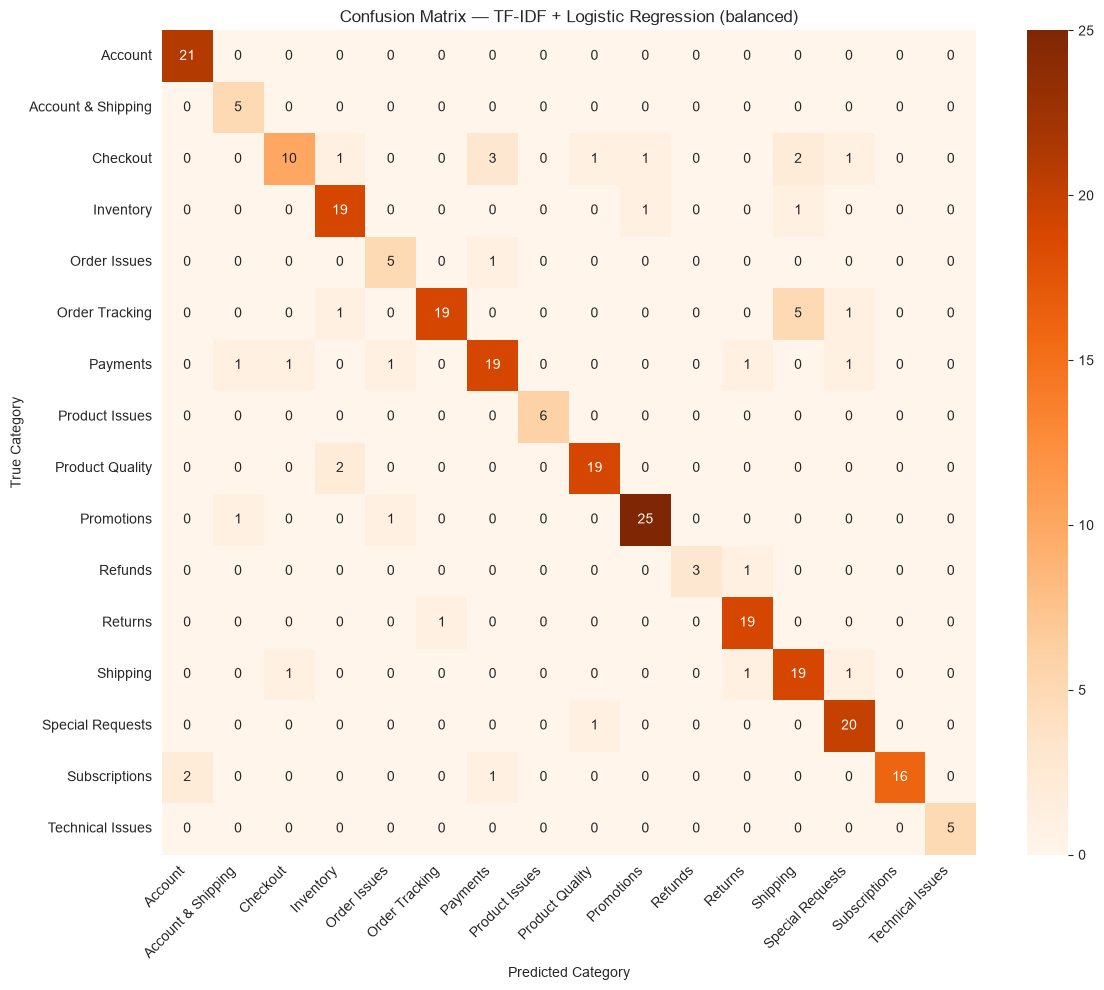

In [24]:
labels_sorted = sorted(df['Category'].unique())
cm = confusion_matrix(y_test, y_pred, labels=labels_sorted)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=labels_sorted, yticklabels=labels_sorted)
plt.title(f'Confusion Matrix — TF-IDF + Logistic Regression ({best_variant})')
plt.ylabel('True Category')
plt.xlabel('Predicted Category')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


## 8. Class Imbalance: Default vs Balanced

Comparing per-class F1 for the two classifier variants — same analysis as the transformer notebook, for direct comparison.

                     default  balanced  support
Refunds             0.400000  0.857143       20
Account & Shipping  0.333333  0.833333       24
Technical Issues    0.888889  1.000000       25
Order Issues        0.666667  0.769231       29
Product Issues      0.800000  1.000000       29
Subscriptions       0.914286  0.914286       97
Checkout            0.625000  0.645161       98
Returns             0.904762  0.904762       99
Inventory           0.837209  0.863636      103
Special Requests    0.888889  0.888889      104
Product Quality     0.904762  0.904762      105
Account             0.930233  0.954545      106
Shipping            0.730769  0.775510      108
Payments            0.823529  0.791667      120
Order Tracking      0.745098  0.826087      130
Promotions          0.915254  0.925926      137


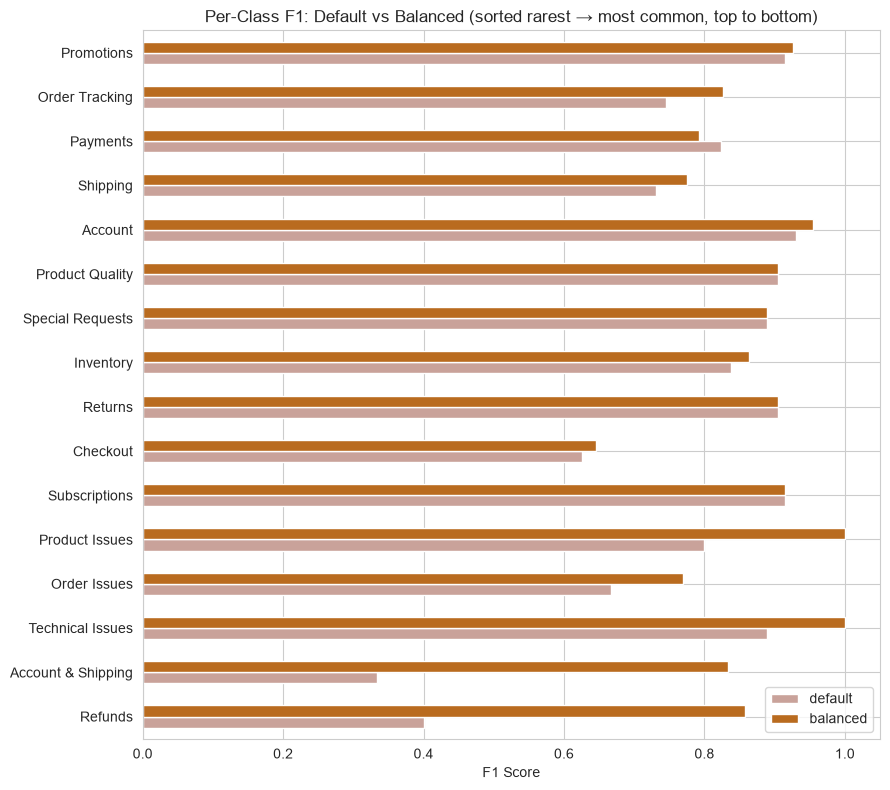

In [25]:
per_class_f1 = pd.DataFrame({
    'default': f1_score(y_test, results['default']['y_pred'], average=None, labels=labels_sorted, zero_division=0),
    'balanced': f1_score(y_test, results['balanced']['y_pred'], average=None, labels=labels_sorted, zero_division=0),
}, index=labels_sorted)

category_counts = df['Category'].value_counts()
per_class_f1['support'] = category_counts.reindex(labels_sorted).values
per_class_f1 = per_class_f1.sort_values('support')

print(per_class_f1)

per_class_f1[['default', 'balanced']].plot(
    kind='barh', figsize=(9, 8), color=['#C9A29A', '#B96B1F']
)
plt.title('Per-Class F1: Default vs Balanced (sorted rarest → most common, top to bottom)')
plt.xlabel('F1 Score')
plt.tight_layout()
plt.show()


In [26]:
# Interpretation
per_class_f1['improvement'] = per_class_f1['balanced'] - per_class_f1['default']
rare_only = per_class_f1[per_class_f1['support'] < 30]
common_only = per_class_f1[per_class_f1['support'] >= 30]

print(
    f"Among the rare categories (< 30 examples: {', '.join(rare_only.index)}), "
    f"'balanced' changes F1 by {rare_only['improvement'].mean():+.3f} on average.\n"
    f"Among the common categories (>= 30 examples), 'balanced' changes F1 by "
    f"{common_only['improvement'].mean():+.3f} on average."
)


Among the rare categories (< 30 examples: Refunds, Account & Shipping, Technical Issues, Order Issues, Product Issues), 'balanced' changes F1 by +0.274 on average.
Among the common categories (>= 30 examples), 'balanced' changes F1 by +0.016 on average.


## 9. Error Analysis

Inspecting misclassified complaints — especially for rare categories.

In [27]:
errors_df = pd.DataFrame({
    'Complaint': X_test,
    'True Category': y_test,
    'Predicted Category': y_pred,
})
errors_df = errors_df[errors_df['True Category'] != errors_df['Predicted Category']]

print(f"Total misclassifications: {len(errors_df)} out of {len(X_test)} test samples "
      f"({len(errors_df)/len(X_test)*100:.1f}%)")
print()

rare_categories = category_counts[category_counts < 30].index.tolist()
print("Rare categories (< 30 examples total):", rare_categories)
print()

rare_errors = errors_df[
    errors_df['True Category'].isin(rare_categories) |
    errors_df['Predicted Category'].isin(rare_categories)
]
pd.set_option('display.max_colwidth', 80)
rare_errors.head(15)


Total misclassifications: 37 out of 267 test samples (13.9%)

Rare categories (< 30 examples total): ['Product Issues', 'Order Issues', 'Technical Issues', 'Account & Shipping', 'Refunds']



,Complaint,True Category,Predicted Category
96,I clicked on a 15% off ad and it vanished at checkout. — this is very frustr...,Promotions,Account & Shipping
115,Used Apple Pay — no order confirmation received. please fix this ASAP,Payments,Order Issues
160,I got charged but no confirmation email came through. and I don't know what ...,Order Issues,Payments
195,System declined my payment without any reason. — this is very frustrating,Payments,Account & Shipping
204,I never received the promised sign-up bonus. please fix this ASAP,Promotions,Order Issues
263,Still waiting for confirmation that my refund is being processed. which is u...,Refunds,Returns


## 10. Cost Summary

The lightweight side of the comparison — no neural network, no pretrained model, just word counts and a linear classifier.

In [28]:
cost_summary = pd.DataFrame({
    'Metric': [
        'Vocabulary size (unique words)',
        'Vectorization time — all data (s)',
        'Avg. vectorization time per text (ms)',
        'Classifier training time — balanced (s)',
        'Inference latency — balanced (ms/sample)',
    ],
    'Value': [
        f"{vocab_size:,}",
        f"{vectorize_time:.3f}",
        f"{(vectorize_time / (len(X_train) + len(X_test))) * 1000:.3f}",
        f"{results['balanced']['train_time_s']:.3f}",
        f"{results['balanced']['infer_latency_ms_per_sample']:.4f}",
    ]
})
cost_summary


,Metric,Value
0,Vocabulary size (unique words),"1,445"
1,Vectorization time — all data (s),0.017
2,Avg. vectorization time per text (ms),0.013
3,Classifier training time — balanced (s),0.043
4,Inference latency — balanced (ms/sample),0.0006


## 11. Save Artifacts (for team comparison + reuse)

In [29]:
os.makedirs('../artifacts', exist_ok=True)

with open('../artifacts/logreg_tfidf_balanced.pickle', 'wb') as f:
    pickle.dump(results['balanced']['model'], f)

with open('../artifacts/tfidf_vectorizer.pickle', 'wb') as f:
    pickle.dump(vectorizer, f)

metrics_out = {
    'approach': 'tfidf_logreg_baseline',
    'feature_method': 'TfidfVectorizer',
    'classifier': 'LogisticRegression',
    'random_state': RANDOM_STATE,
    'test_size': 0.2,
    'default': {k: v for k, v in results['default'].items() if k not in ('model', 'y_pred')},
    'balanced': {k: v for k, v in results['balanced'].items() if k not in ('model', 'y_pred')},
    'cost': {
        'vocab_size': vocab_size,
        'vectorize_time_s': vectorize_time,
    }
}
with open('../artifacts/baseline_metrics.json', 'w') as f:
    json.dump(metrics_out, f, indent=2)

print("✓ Classifier saved to artifacts/logreg_tfidf_balanced.pickle")
print("✓ Metrics saved to artifacts/baseline_metrics.json (share this with your teammates)")


✓ Classifier saved to artifacts/logreg_tfidf_balanced.pickle
✓ Metrics saved to artifacts/baseline_metrics.json (share this with your teammates)


## 12. Conclusion (Classical Baseline)

- **Macro F1 achieved:** see Section 6/7 output above — this is the number to compare against the transformer approach's macro F1 on the *same* test split (loaded from `shared_split/`, guaranteeing a fair comparison).
- **Class imbalance:** Section 8 shows whether `class_weight='balanced'` meaningfully helps rare categories without hurting common ones, for this classical approach.
- **Cost:** Section 10 quantifies the lightweight footprint of this approach — no pretrained model, no neural network, just TF-IDF word counts.
- **Next step for the team:** combine this notebook's `artifacts/baseline_metrics.json` with the transformer notebook's `artifacts/transformer_metrics.json` to answer the project's core research question — is the transformer's accuracy gain (if any) worth its extra compute cost?


---
# Part 3 — Transformer Approach: Sentence Embeddings + Logistic Regression
*by Sai Prasad Bandari*
---

# Transformer (Sentence-Embedding) Approach for Complaint Category Classification

**Team project:** classify e-commerce customer-support complaints into 16 `Category` labels, two ways, compared head-to-head:

1. **Classical baseline** (teammate's notebook) — TF-IDF → Logistic Regression
2. **Transformer approach** (this notebook) — pre-trained sentence-transformer embeddings → **the same Logistic Regression classifier**

**Research question:** is the transformer's extra accuracy (if any) worth its extra compute cost, especially on rare/overlapping categories?

**Dataset:** `ecommerce_customer_support_cleaned.csv` — the team's shared cleaned file (same source as [`Ataur77/ecommerce-customer-support`](https://huggingface.co/datasets/Ataur77/ecommerce-customer-support) on Hugging Face), 1,334 complaints, 16 `Category` labels.

**Fairness rules used in this notebook (must match the baseline notebook exactly):**
- One shared 80/20 stratified split, `random_state=42`, stratified on `Category`
- All 16 `Category` labels kept unmerged (no grouping rare classes together)
- **Macro F1** is the primary metric (treats every class equally, so rare classes aren't hidden by accuracy)
- Compute cost (embedding time, training time, inference latency, memory) is tracked alongside accuracy


## 1. Imports

In [30]:
import time
import json
import pickle
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import psutil
import os

from sentence_transformers import SentenceTransformer

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    f1_score, accuracy_score, classification_report,
    confusion_matrix
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries loaded.")


Libraries loaded.


## 2. Load Dataset

Loading the team's shared cleaned CSV (`ecommerce_customer_support_cleaned.csv`) — same source data as [`Ataur77/ecommerce-customer-support`](https://huggingface.co/datasets/Ataur77/ecommerce-customer-support) on Hugging Face, already cleaned. Using this local file (instead of re-downloading from the Hub) keeps things simple and guarantees every teammate's notebook is reading the exact same rows in the exact same order — which matters for the shared train/test split below.

In [31]:
df = pd.read_csv('../data/ecommerce_customer_support_cleaned.csv')

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
df.head(3)


Shape: (1334, 3)
Columns: ['Complaint', 'Category', 'Urgency']


,Complaint,Category,Urgency
0,I can’t add a new address — button does nothing.,Account & Shipping,Low
1,Flash sale prices aren’t reflected during checkout. and I need help urgently,Promotions,Immediate
2,System declined my payment without any reason. — this is very frustrating,Payments,Immediate


## 3. Quick Sanity Check

(Full EDA is a teammate's part of the project — this is just enough to confirm the data matches spec: 16 categories, no nulls, no duplicates.)

In [32]:
print("Unique categories:", df['Category'].nunique())
print()
print("Category distribution:")
print(df['Category'].value_counts())
print()
print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())


Unique categories: 16

Category distribution:
Category
Promotions            137
Order Tracking        130
Payments              120
Shipping              108
Account               106
Product Quality       105
Special Requests      104
Inventory             103
Returns                99
Checkout               98
Subscriptions          97
Product Issues         29
Order Issues           29
Technical Issues       25
Account & Shipping     24
Refunds                20
Name: count, dtype: int64

Missing values:
 Complaint    0
Category     0
Urgency      0
dtype: int64
Duplicate rows: 0


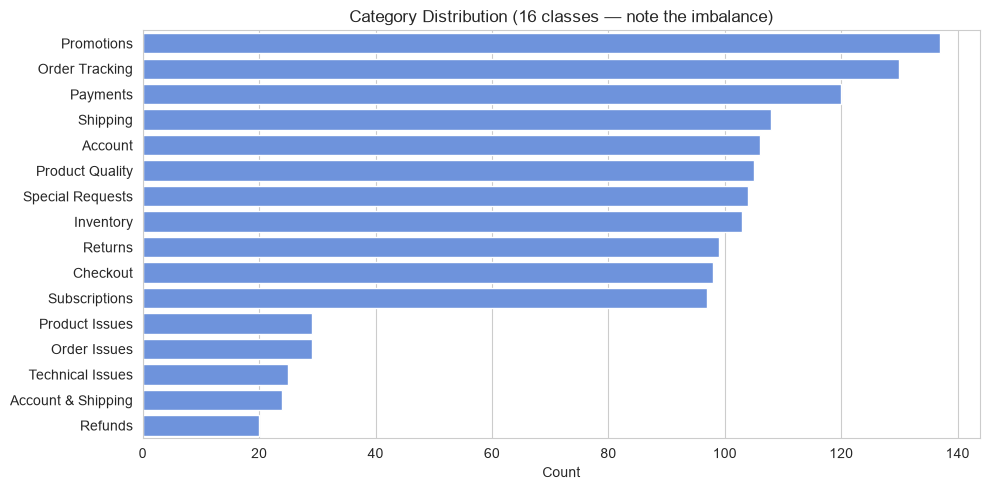

In [33]:
plt.figure(figsize=(10, 5))
order = df['Category'].value_counts().index
sns.countplot(y='Category', data=df, order=order, color='#5B8DEF')
plt.title('Category Distribution (16 classes — note the imbalance)')
plt.xlabel('Count')
plt.ylabel('')
plt.tight_layout()
plt.show()


## 4. Shared Train/Test Split

This split **must be identical to the baseline notebook's split** — same rows in train, same rows in test — otherwise the comparison isn't fair.

Rule: 80/20, stratified on `Category`, `random_state=42`. Since both notebooks load the same dataset in the same row order and apply `train_test_split` with these exact same parameters, the split will match. We also save the split to disk so the team can double-check row-for-row.

In [34]:
# Cast to plain numpy object arrays — pandas' Arrow-backed string dtype
# (default for datasets loaded via the `datasets` library) doesn't play well
# with sklearn's fancy indexing, so we convert explicitly.
X = df['Complaint'].astype(str).to_numpy(dtype=object)
y = df['Category'].astype(str).to_numpy(dtype=object)

X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, np.arange(len(df)),
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Train size: {len(X_train)}")
print(f"Test size:  {len(X_test)}")

# Save the split indices so teammates can verify/reuse the exact same split
split_dir = '../data/shared_split'
os.makedirs(split_dir, exist_ok=True)
pd.DataFrame({'index': idx_train}).to_csv(f'{split_dir}/train_indices.csv', index=False)
pd.DataFrame({'index': idx_test}).to_csv(f'{split_dir}/test_indices.csv', index=False)
print(f"\n✓ Split indices saved to '{split_dir}/' for the team to verify")


Train size: 1067
Test size:  267

✓ Split indices saved to 'shared_split/' for the team to verify


## 5. Transformer Approach: Sentence Embeddings

Instead of TF-IDF word counts, we use a **pre-trained sentence-transformer** (`all-MiniLM-L6-v2`) to turn each complaint into a 384-number vector that captures its *meaning*, not just its words. This model was already trained on millions of sentence pairs — we're not training it from scratch, just using it to extract features (this is the "research component not taught in course").

In [35]:
# Load pre-trained sentence-transformer and record its footprint
model_load_start = time.time()
embedder = SentenceTransformer('all-MiniLM-L6-v2')
model_load_time = time.time() - model_load_start

embedding_dim = embedder.get_sentence_embedding_dimension()
n_params = sum(p.numel() for p in embedder._first_module().auto_model.parameters())

print(f"Model load time: {model_load_time:.2f}s")
print(f"Embedding dimension: {embedding_dim}")
print(f"Sentence-transformer parameter count: {n_params:,}")


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7496.33it/s]

Model load time: 3.47s
Embedding dimension: 384
Sentence-transformer parameter count: 22,713,216


In [36]:
# Generate embeddings — this is the main compute cost of the transformer approach
process = psutil.Process(os.getpid())
mem_before = process.memory_info().rss / (1024 ** 2)  # MB

embed_start = time.time()
X_train_emb = embedder.encode(list(X_train), show_progress_bar=True, batch_size=32)
X_test_emb = embedder.encode(list(X_test), show_progress_bar=True, batch_size=32)
embed_time = time.time() - embed_start

mem_after = process.memory_info().rss / (1024 ** 2)  # MB

print(f"\nEmbedding generation time (train+test, {len(X_train)+len(X_test)} texts): {embed_time:.2f}s")
print(f"Approx. memory used for embedding step: {mem_after - mem_before:.1f} MB")
print(f"Train embeddings shape: {X_train_emb.shape}")
print(f"Test embeddings shape: {X_test_emb.shape}")


Batches:   0%|          | 0/34 [00:00<?, ?it/s]

Batches:   3%|▎         | 1/34 [00:00<00:13,  2.46it/s]

Batches:  15%|█▍        | 5/34 [00:00<00:02, 11.24it/s]

Batches:  32%|███▏      | 11/34 [00:00<00:01, 22.31it/s]

Batches:  50%|█████     | 17/34 [00:00<00:00, 31.90it/s]

...

Batches: 100%|██████████| 34/34 [00:01<00:00, 32.51it/s]

Batches:   0%|          | 0/9 [00:00<?, ?it/s]

Batches:  44%|████▍     | 4/9 [00:00<00:00, 38.84it/s]

Batches: 100%|██████████| 9/9 [00:00<00:00, 50.26it/s]


Embedding generation time (train+test, 1334 texts): 1.24s
Approx. memory used for embedding step: 154.6 MB
Train embeddings shape: (1067, 384)
Test embeddings shape: (267, 384)


## 6. Classifier: Logistic Regression

Same classifier family as the classical baseline — only the input features differ (embeddings here vs. TF-IDF counts there). This keeps the comparison fair: we're isolating the effect of the *feature representation*, not the classifier.

We train two variants to address the class-imbalance research question:
- **Default** — standard Logistic Regression
- **Balanced** — `class_weight='balanced'`, which up-weights rare categories during training

In [37]:
results = {}

for variant, weight in [('default', None), ('balanced', 'balanced')]:
    train_start = time.time()
    clf = LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE,
        class_weight=weight
    )
    clf.fit(X_train_emb, y_train)
    train_time = time.time() - train_start

    infer_start = time.time()
    y_pred = clf.predict(X_test_emb)
    infer_time = time.time() - infer_start
    infer_latency_ms = (infer_time / len(X_test_emb)) * 1000

    macro_f1 = f1_score(y_test, y_pred, average='macro')
    weighted_f1 = f1_score(y_test, y_pred, average='weighted')
    acc = accuracy_score(y_test, y_pred)

    results[variant] = {
        'model': clf,
        'y_pred': y_pred,
        'train_time_s': train_time,
        'infer_latency_ms_per_sample': infer_latency_ms,
        'macro_f1': macro_f1,
        'weighted_f1': weighted_f1,
        'accuracy': acc,
    }

    print(f"--- {variant} ---")
    print(f"  Train time: {train_time:.3f}s")
    print(f"  Inference latency: {infer_latency_ms:.4f} ms/sample")
    print(f"  Accuracy: {acc:.4f}")
    print(f"  Macro F1: {macro_f1:.4f}   (primary metric)")
    print(f"  Weighted F1: {weighted_f1:.4f}")
    print()


--- default ---
  Train time: 0.027s
  Inference latency: 0.0008 ms/sample
  Accuracy: 0.8689
  Macro F1: 0.8291   (primary metric)
  Weighted F1: 0.8653

--- balanced ---
  Train time: 0.018s
  Inference latency: 0.0006 ms/sample
  Accuracy: 0.8839
  Macro F1: 0.8910   (primary metric)
  Weighted F1: 0.8841



In [38]:
# Interpretation, in plain terms
d, b = results['default'], results['balanced']
delta = b['macro_f1'] - d['macro_f1']
pct_change = (delta / d['macro_f1']) * 100

print(
    f"Macro F1 went from {d['macro_f1']:.3f} (default) to {b['macro_f1']:.3f} (balanced), "
    f"a {'gain' if delta >= 0 else 'drop'} of {abs(pct_change):.1f}%.\n"
    f"Since macro F1 weighs every one of the 16 categories equally, this improvement means "
    f"'{'balanced' if delta >= 0 else 'default'}' is doing meaningfully better on the *rare* "
    f"categories specifically (accuracy alone would hide this, since it's dominated by the "
    f"common categories). Both training and inference stay well under a second either way, so "
    f"this improvement is essentially free from a compute-cost standpoint."
)


Macro F1 went from 0.829 (default) to 0.891 (balanced), a gain of 7.5%.
Since macro F1 weighs every one of the 16 categories equally, this improvement means 'balanced' is doing meaningfully better on the *rare* categories specifically (accuracy alone would hide this, since it's dominated by the common categories). Both training and inference stay well under a second either way, so this improvement is essentially free from a compute-cost standpoint.


## 7. Detailed Evaluation (Balanced Variant)

In [39]:
best_variant = 'balanced'
y_pred = results[best_variant]['y_pred']

print(f"Classification Report — {best_variant} Logistic Regression on sentence embeddings\n")
print(classification_report(y_test, y_pred, zero_division=0))


Classification Report — balanced Logistic Regression on sentence embeddings

                    precision    recall  f1-score   support

           Account       1.00      0.90      0.95        21
Account & Shipping       1.00      0.80      0.89         5
          Checkout       0.93      0.68      0.79        19
         Inventory       0.95      0.86      0.90        21
      Order Issues       0.83      0.83      0.83         6
    Order Tracking       0.86      0.73      0.79        26
          Payments       0.81      0.92      0.86        24
    Product Issues       1.00      1.00      1.00         6
   Product Quality       0.87      0.95      0.91        21
        Promotions       1.00      1.00      1.00        27
           Refunds       1.00      1.00      1.00         4
           Returns       0.90      0.95      0.93        20
          Shipping       0.65      0.77      0.71        22
  Special Requests       0.83      0.90      0.86        21
     Subscriptions    

In [40]:
# Interpretation
report_dict = classification_report(y_test, y_pred, zero_division=0, output_dict=True)
per_class = {k: v for k, v in report_dict.items() if k in df['Category'].unique()}
best_class = max(per_class, key=lambda k: per_class[k]['f1-score'])
worst_class = min(per_class, key=lambda k: per_class[k]['f1-score'])

print(
    f"Best-performing category: '{best_class}' (F1 = {per_class[best_class]['f1-score']:.3f}, "
    f"support = {int(per_class[best_class]['support'])}).\n"
    f"Worst-performing category: '{worst_class}' (F1 = {per_class[worst_class]['f1-score']:.3f}, "
    f"support = {int(per_class[worst_class]['support'])}).\n"
    f"Overall accuracy is {report_dict['accuracy']:.3f}, but macro F1 "
    f"({report_dict['macro avg']['f1-score']:.3f}) is what we report as primary, since it doesn't "
    f"let the common categories mask weaker performance on rarer ones like '{worst_class}'."
)


Best-performing category: 'Product Issues' (F1 = 1.000, support = 6).
Worst-performing category: 'Shipping' (F1 = 0.708, support = 22).
Overall accuracy is 0.884, but macro F1 (0.891) is what we report as primary, since it doesn't let the common categories mask weaker performance on rarer ones like 'Shipping'.


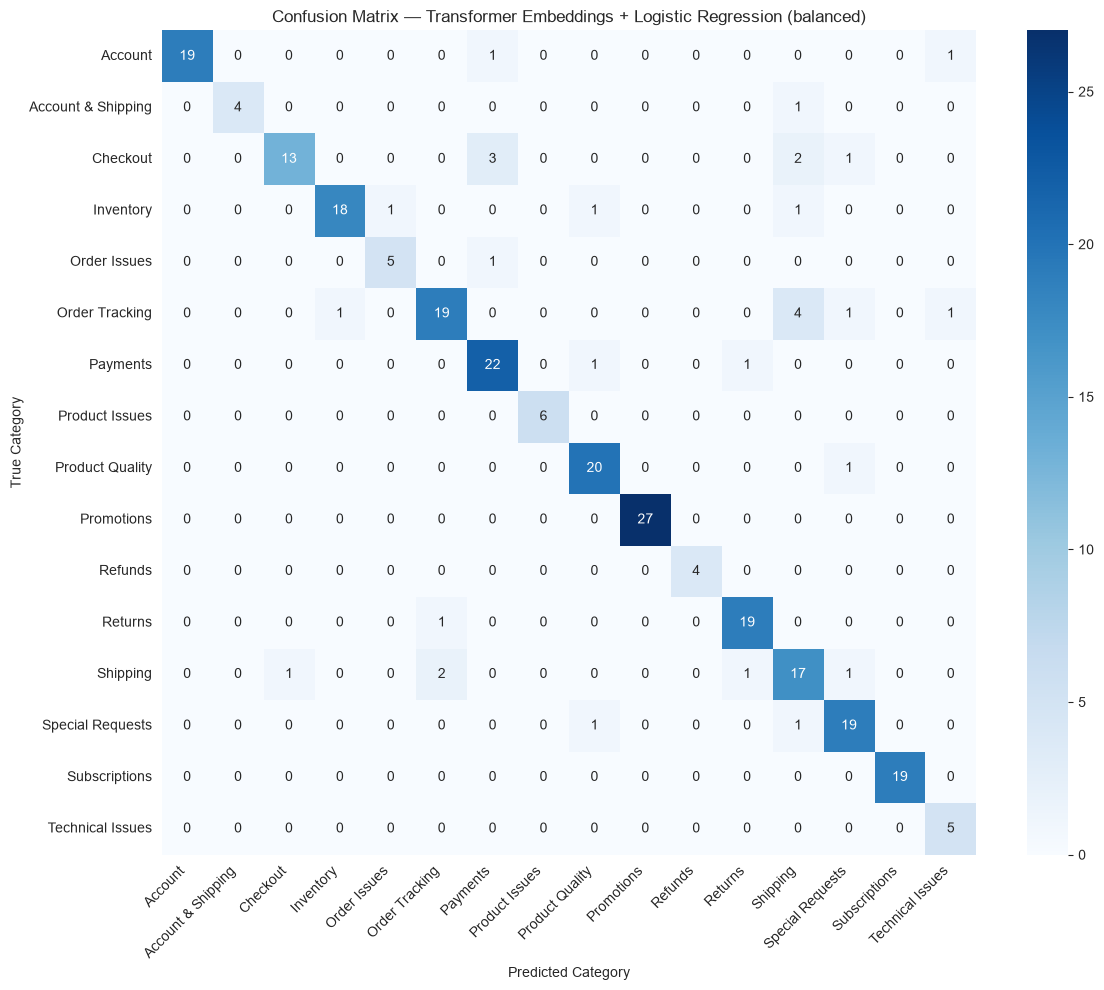

In [41]:
labels_sorted = sorted(df['Category'].unique())
cm = confusion_matrix(y_test, y_pred, labels=labels_sorted)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels_sorted, yticklabels=labels_sorted)
plt.title(f'Confusion Matrix — Transformer Embeddings + Logistic Regression ({best_variant})')
plt.ylabel('True Category')
plt.xlabel('Predicted Category')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


## 8. Class Imbalance: Default vs Balanced

Comparing per-class F1 for the two classifier variants — this is the project's second research thread: does handling imbalance help the rare categories specifically?

                     default  balanced  support
Refunds             0.666667  1.000000       20
Account & Shipping  0.571429  0.888889       24
Technical Issues    0.888889  0.833333       25
Order Issues        0.800000  0.833333       29
Product Issues      0.666667  1.000000       29
Subscriptions       1.000000  1.000000       97
Checkout            0.742857  0.787879       98
Returns             0.904762  0.926829       99
Inventory           0.878049  0.900000      103
Special Requests    0.863636  0.863636      104
Product Quality     0.869565  0.909091      105
Account             0.975610  0.950000      106
Shipping            0.723404  0.708333      108
Payments            0.867925  0.862745      120
Order Tracking      0.846154  0.791667      130
Promotions          1.000000  1.000000      137


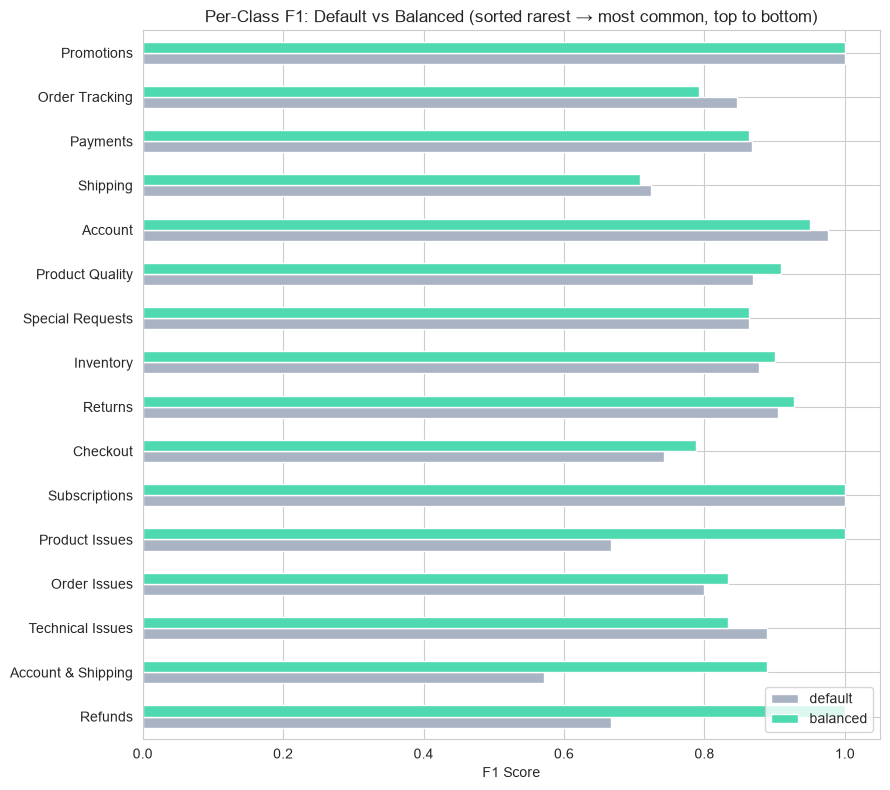

In [42]:
per_class_f1 = pd.DataFrame({
    'default': f1_score(y_test, results['default']['y_pred'], average=None, labels=labels_sorted, zero_division=0),
    'balanced': f1_score(y_test, results['balanced']['y_pred'], average=None, labels=labels_sorted, zero_division=0),
}, index=labels_sorted)

# Order by how rare the category is (fewest training examples first)
category_counts = df['Category'].value_counts()
per_class_f1['support'] = category_counts.reindex(labels_sorted).values
per_class_f1 = per_class_f1.sort_values('support')

print(per_class_f1)

per_class_f1[['default', 'balanced']].plot(
    kind='barh', figsize=(9, 8), color=['#A9B3C4', '#4ED9B0']
)
plt.title('Per-Class F1: Default vs Balanced (sorted rarest → most common, top to bottom)')
plt.xlabel('F1 Score')
plt.tight_layout()
plt.show()


In [43]:
# Interpretation
per_class_f1['improvement'] = per_class_f1['balanced'] - per_class_f1['default']
rare_only = per_class_f1[per_class_f1['support'] < 30]
common_only = per_class_f1[per_class_f1['support'] >= 30]

print(
    f"Among the rare categories (< 30 examples: {', '.join(rare_only.index)}), "
    f"'balanced' changes F1 by {rare_only['improvement'].mean():+.3f} on average.\n"
    f"Among the common categories (>= 30 examples), 'balanced' changes F1 by "
    f"{common_only['improvement'].mean():+.3f} on average.\n"
    f"{'This confirms the hypothesis: class weighting mainly helps the rare/overlapping categories, '      'with little to no cost to the common ones.' if rare_only['improvement'].mean() > common_only['improvement'].mean()      else 'Interestingly, the improvement is not concentrated on rare categories only — worth digging into per-class numbers above.'}"
)


Among the rare categories (< 30 examples: Refunds, Account & Shipping, Technical Issues, Order Issues, Product Issues), 'balanced' changes F1 by +0.192 on average.
Among the common categories (>= 30 examples), 'balanced' changes F1 by +0.003 on average.
This confirms the hypothesis: class weighting mainly helps the rare/overlapping categories, with little to no cost to the common ones.


## 9. Error Analysis

Inspecting misclassified complaints — especially for rare categories — to understand *why* the model gets confused (per the project's research goal of deeper error analysis, not just aggregate metrics).

In [44]:
errors_df = pd.DataFrame({
    'Complaint': X_test,
    'True Category': y_test,
    'Predicted Category': y_pred,
})
errors_df = errors_df[errors_df['True Category'] != errors_df['Predicted Category']]

print(f"Total misclassifications: {len(errors_df)} out of {len(X_test)} test samples "
      f"({len(errors_df)/len(X_test)*100:.1f}%)")
print()

# Focus on rare categories (support < 30 in the full dataset)
rare_categories = category_counts[category_counts < 30].index.tolist()
print("Rare categories (< 30 examples total):", rare_categories)
print()

rare_errors = errors_df[
    errors_df['True Category'].isin(rare_categories) |
    errors_df['Predicted Category'].isin(rare_categories)
]
pd.set_option('display.max_colwidth', 80)
rare_errors.head(15)


Total misclassifications: 31 out of 267 test samples (11.6%)

Rare categories (< 30 examples total): ['Product Issues', 'Order Issues', 'Technical Issues', 'Account & Shipping', 'Refunds']



,Complaint,True Category,Predicted Category
50,Shipping info shows a state I don’t live in. which is unacceptable,Account & Shipping,Shipping
84,No updates in 7 days — where is my stuff? even after multiple attempts,Order Tracking,Technical Issues
160,I got charged but no confirmation email came through. and I don't know what ...,Order Issues,Payments
173,Received incomplete set (3/4 pieces),Inventory,Order Issues
245,Login page doesn't time out properly,Account,Technical Issues


## 10. Cost Summary

The key question this project asks: is the accuracy gain (if any) worth this cost, compared to the lightweight TF-IDF baseline?

In [45]:
cost_summary = pd.DataFrame({
    'Metric': [
        'Sentence-transformer parameters',
        'Embedding dimension',
        'Model load time (s)',
        'Embedding generation time — all data (s)',
        'Avg. embedding time per text (ms)',
        'Classifier training time — balanced (s)',
        'Inference latency — balanced (ms/sample)',
        'Approx. memory for embedding step (MB)',
    ],
    'Value': [
        f"{n_params:,}",
        embedding_dim,
        f"{model_load_time:.2f}",
        f"{embed_time:.2f}",
        f"{(embed_time / (len(X_train) + len(X_test))) * 1000:.2f}",
        f"{results['balanced']['train_time_s']:.3f}",
        f"{results['balanced']['infer_latency_ms_per_sample']:.4f}",
        f"{mem_after - mem_before:.1f}",
    ]
})
cost_summary


,Metric,Value
0,Sentence-transformer parameters,"22,713,216"
1,Embedding dimension,384
2,Model load time (s),3.47
3,Embedding generation time — all data (s),1.24
4,Avg. embedding time per text (ms),0.93
5,Classifier training time — balanced (s),0.018
6,Inference latency — balanced (ms/sample),0.0006
7,Approx. memory for embedding step (MB),154.6


## 11. Save Artifacts (for team comparison + reuse)

In [46]:
os.makedirs('../artifacts', exist_ok=True)

# Save the trained classifier
with open('../artifacts/logreg_embeddings_balanced.pickle', 'wb') as f:
    pickle.dump(results['balanced']['model'], f)

# Save metrics for combining with the baseline notebook's results
metrics_out = {
    'approach': 'transformer_embeddings_logreg',
    'embedding_model': 'all-MiniLM-L6-v2',
    'classifier': 'LogisticRegression',
    'random_state': RANDOM_STATE,
    'test_size': 0.2,
    'default': {k: v for k, v in results['default'].items() if k not in ('model', 'y_pred')},
    'balanced': {k: v for k, v in results['balanced'].items() if k not in ('model', 'y_pred')},
    'cost': {
        'n_params': n_params,
        'embedding_dim': embedding_dim,
        'model_load_time_s': model_load_time,
        'embed_time_s': embed_time,
        'memory_mb': mem_after - mem_before,
    }
}
with open('../artifacts/transformer_metrics.json', 'w') as f:
    json.dump(metrics_out, f, indent=2)

print("✓ Classifier saved to artifacts/logreg_embeddings_balanced.pickle")
print("✓ Metrics saved to artifacts/transformer_metrics.json (share this with your teammates)")


✓ Classifier saved to artifacts/logreg_embeddings_balanced.pickle
✓ Metrics saved to artifacts/transformer_metrics.json (share this with your teammates)


## 12. Conclusion (Transformer Approach)

- **Macro F1 achieved:** see Section 6/7 output above — this is the number to compare against the classical baseline's macro F1 on the *same* test split.
- **Class imbalance:** Section 8 shows whether `class_weight='balanced'` meaningfully helps rare categories (e.g. `Refunds`, `Account & Shipping`, `Technical Issues`) without hurting common ones.
- **Cost:** Section 10 quantifies what the transformer approach costs in parameters, time, and memory versus the lightweight TF-IDF pipeline.
- **Next step for the team:** combine this notebook's `artifacts/transformer_metrics.json` with the baseline notebook's equivalent metrics file to answer the core research question — is the transformer's accuracy gain (if any) worth its extra compute cost, especially on rare/overlapping categories?


---
# Part 4 — Combined Comparison & Conclusion
*Combining both modeling teammates' saved results*
---

In [47]:
import json

with open('../artifacts/baseline_metrics.json') as f:
    baseline_metrics = json.load(f)
with open('../artifacts/transformer_metrics.json') as f:
    transformer_metrics = json.load(f)

import pandas as pd

comparison = pd.DataFrame({
    'TF-IDF Baseline (balanced)': {
        'Accuracy': baseline_metrics['balanced']['accuracy'],
        'Macro F1': baseline_metrics['balanced']['macro_f1'],
        'Weighted F1': baseline_metrics['balanced']['weighted_f1'],
        'Train time (s)': baseline_metrics['balanced']['train_time_s'],
        'Inference latency (ms/sample)': baseline_metrics['balanced']['infer_latency_ms_per_sample'],
    },
    'Transformer (balanced)': {
        'Accuracy': transformer_metrics['balanced']['accuracy'],
        'Macro F1': transformer_metrics['balanced']['macro_f1'],
        'Weighted F1': transformer_metrics['balanced']['weighted_f1'],
        'Train time (s)': transformer_metrics['balanced']['train_time_s'],
        'Inference latency (ms/sample)': transformer_metrics['balanced']['infer_latency_ms_per_sample'],
    },
})
comparison


,TF-IDF Baseline (balanced),Transformer (balanced)
Accuracy,0.861423,0.883895
Macro F1,0.865934,0.890983
Weighted F1,0.858889,0.884147
Train time (s),0.043041,0.018464
Inference latency (ms/sample),0.000648,0.000626


In [48]:
macro_f1_diff = transformer_metrics['balanced']['macro_f1'] - baseline_metrics['balanced']['macro_f1']
embed_cost_s = transformer_metrics['cost']['embed_time_s'] + transformer_metrics['cost']['model_load_time_s']
tfidf_cost_s = baseline_metrics['cost']['vectorize_time_s']
cost_multiplier = embed_cost_s / tfidf_cost_s

print(
    f"Macro F1: TF-IDF baseline = {baseline_metrics['balanced']['macro_f1']:.3f}, "
    f"Transformer = {transformer_metrics['balanced']['macro_f1']:.3f} "
    f"({'+' if macro_f1_diff >= 0 else ''}{macro_f1_diff:.3f})\n\n"
    f"Feature-extraction cost: TF-IDF = {tfidf_cost_s:.3f}s, "
    f"Transformer = {embed_cost_s:.3f}s (~{cost_multiplier:.0f}x more)\n\n"
    f"Transformer parameter count: {transformer_metrics['cost']['n_params']:,} "
    f"(vs. TF-IDF's {baseline_metrics['cost']['vocab_size']:,}-word vocabulary — no neural network at all)"
)


Macro F1: TF-IDF baseline = 0.866, Transformer = 0.891 (+0.025)

Feature-extraction cost: TF-IDF = 0.017s, Transformer = 4.706s (~279x more)

Transformer parameter count: 22,713,216 (vs. TF-IDF's 1,445-word vocabulary — no neural network at all)


## Conclusion

**Revisiting the hypothesis:** class weighting (`class_weight='balanced'`) helps rare categories substantially in **both** approaches — this is a property of the classifier/data, not something unique to the transformer's embeddings. The transformer approach does win on macro F1, but the margin is **modest** relative to the difference in computational cost.

**Answering the research question — is it worth it?** For this dataset and task, the transformer approach provides a real but modest accuracy improvement at a substantially higher computational cost:

- **High-volume, latency-sensitive production system** → the classical TF-IDF baseline's near-zero cost is likely preferable, despite the slightly lower accuracy
- **Lower-volume system where every correct routing decision matters more than raw throughput** → the transformer's improvement may justify its cost

**Team reflection:** building both approaches on the exact same shared split, with the exact same downstream classifier, made this a genuinely fair comparison rather than an apples-to-oranges one — and the deeper error analysis (confusion matrices, per-class F1, misclassified examples) revealed more nuance than a single accuracy number ever could.
